<a href="https://colab.research.google.com/github/jacobhroutzong/Decision-Models/blob/main/Decision_Model_Kev_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Reset directory
%cd /content

# 2. Strip incompatible pre-installed binary packages (prevents PyTorch ABI and PEFT crashes)
!pip uninstall -y torchvision torchaudio torchao >/dev/null 2>&1 || true

# 3. Clean clone of Kev repository
!rm -rf /content/kev
!git clone https://github.com/jaredpalmer/kev.git
%cd /content/kev

# 4. Install Kev server, TypeSafe SDK, and UI utilities
!pip install -q uv
!uv pip install --system -e ".[serve]"
!pip install -q typesafe-sdk rich matplotlib

/content
Cloning into 'kev'...
remote: Enumerating objects: 11213, done.
remote: Counting objects: 100% (2613/2613), done.
remote: Compressing objects: 100% (629/629), done.
remote: Total 11213 (delta 2233), reused 2020 (delta 1958), pack-reused 8600 (from 2)
Receiving objects: 100% (11213/11213), 167.83 MiB | 19.90 MiB/s, done.
Resolving deltas: 100% (6986/6986), done.
Updating files: 100% (3051/3051), done.
/content/kev
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 126.6 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 92 packages in 495ms
Prepared 20 packages in 28.69s
Uninstalled 15 packages in 711ms
Installed 20 packages in 189ms
 + kev==0.1.0 (from file:///content/kev)
 - numpy==2.1.3
 + numpy==2.5.4
 - nvidia-cublas-cu12==12.9.2.10
 + nvidia-cublas-cu12==12.8.4.1
 - nvidia-cuda-cupti-cu12==12.9.79
 + nvidia-cuda-cupti-cu12==12.8.90
 - nvidia-cuda-nvrtc-cu12==12.9.86
 + nvidia-cuda-nvrtc-cu12==12.8.93
 - nvidia-cuda-runtime-cu12==12.9.79
 + nvidia-cu

In [2]:
import subprocess
import time
import socket

MODEL_ID = "jaredpalmer/kev-4b"
PORT = 8009

# Clean up any leftover processes on the port
!fuser -k 8009/tcp 2>/dev/null || true

print(f"Launching Kev server ({MODEL_ID}) on port {PORT}...")
process = subprocess.Popen(
    ["python", "-u", "-m", "kev.serve", "--run", MODEL_ID, "--port", str(PORT)],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

server_ready = False
start_time = time.time()

# Stream logs in real-time until the server is ready
while time.time() - start_time < 300:
    line = process.stdout.readline()
    if line:
        print(line, end="")

    if process.poll() is not None:
        remaining = process.stdout.read()
        if remaining:
            print(remaining)
        print(f"\n[ERROR] Server process died with code {process.returncode}")
        break

    try:
        with socket.create_connection(("127.0.0.1", PORT), timeout=0.5):
            server_ready = True
            print(f"\n Server is LIVE and listening on http://127.0.0.1:{PORT}!")
            break
    except (ConnectionRefusedError, OSError):
        pass

if not server_ready and process.poll() is None:
    print("\nServer is still initializing weights...")

Launching Kev server (jaredpalmer/kev-4b) on port 8009...

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.

Fetching 13 files: 100%|██████████| 13/13 [00:02<00:00,  4.49it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:31<00:00, 15.83s/it]

Loading weights: 100%|██████████| 426/426 [00:00<00:00, 4202.43it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
fused Qwen3.5 kernels off: install the flash-linear-attention version kev/fused_qwen35.py

In [3]:
from typesafe_sdk import TypeSafeClient, Choice, Noul, Score
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

console = Console()
client = TypeSafeClient(
    api_key="local",
    base_url="http://127.0.0.1:8009",
    model="kev-latest"
)

# 1. Domain Payloads
domains = {
    "Airlines (Flight Ops)": {
        "state": (
            "Flight UA2482 (B777-200) inbound to ORD. Chicago O'Hare issued Ground Stop due to "
            "severe thunderstorms and 45kt crosswinds. Aircraft fuel remaining is 38 minutes "
            "above final reserve. Holding pattern at HALIE FL210. Alternate field MKE deteriorating to CAT II."
        ),
        "questions": {
            "dispatch_action": Choice(
                instructions="Determine the immediate tactical flight dispatch action.",
                criteria={
                    "continue_hold": "Fuel reserves allow >=20 min holding; airport acceptance expected.",
                    "divert_alternate": "Holding margin critically thin or alternate minimums declining.",
                    "declare_emergency": "Final reserve fuel threatened or emergency priority required.",
                }
            ),
            "cancellation_risk": Noul(
                instructions="Does this flight face high probability of route cancellation or return-to-gate?"
            ),
            "disruption_severity": Score(
                instructions="Rate the network disruption severity.",
                criteria=[
                    "Minor: Localized delay under 30 minutes.",
                    "Moderate: 30-90 min delay, manageable duty time impact.",
                    "Severe: Misconnected international passengers, curfew risks.",
                    "Critical: Stranded aircraft, crew timeout, cascading cancellations."
                ]
            )
        }
    },
    "S&P 500 (Macro Regime)": {
        "state": (
            "US Core CPI printed at 3.9% YoY vs 3.6% consensus. 10-Year Treasury Yield surged 18 bps to 4.52%. "
            "S&P 500 futures fell 1.6% in pre-market trade with VIX spiking from 14.2 to 19.8. Fed Funds futures "
            "now price in only 25 bps of easing over the next 12 months down from 75 bps prior."
        ),
        "questions": {
            "macro_regime": Choice(
                instructions="Classify the dominant equity market regime.",
                criteria={
                    "risk_on_expansion": "Accommodative policy, benign inflation, expanding multiples.",
                    "stagflation_shock": "Sticky inflation, rising yields, compressed equity valuations.",
                    "liquidity_crunch": "Flight to cash, credit spread widening, disorderly liquidation.",
                }
            ),
            "volatility_breakout": Noul(
                instructions="Will implied volatility (VIX) sustain an upside regime shift?"
            ),
            "drawdown_risk": Score(
                instructions="Assess short-term equity index drawdown probability.",
                criteria=[
                    "Low: Consolidation / shallow dip (<1%).",
                    "Moderate: Standard pull-back (1% to 3%).",
                    "High: Accelerated selling pressure (3% to 6%).",
                    "Extreme: Systematic CTA / risk-parity liquidation (>6%)."
                ]
            )
        }
    },
    "RF Telemetry (Spectrum EW)": {
        "state": (
            "SDR monitoring 2.440 GHz ISM band. Baseband IQ capture shows a periodic narrowband burst "
            "with 80 kHz bandwidth sweeping across 20 MHz every 400us. Received Signal Strength (RSSI) "
            "is -48 dBm with Carrier-to-Noise Ratio (CNR) at 22 dB, causing adjacent-channel desensitization on IEEE 802.15.4 nodes."
        ),
        "questions": {
            "signal_class": Choice(
                instructions="Identify the primary RF emitter classification.",
                criteria={
                    "standard_wifi_ofdm": "Wideband 20/40/80 MHz continuous packet OFDM transmission.",
                    "frequency_hopping_interferer": "Fast narrowband pulse hopper, Bluetooth, or jammer.",
                    "thermal_ambient_noise": "Gaussian distributed background floor without coherent structures.",
                }
            ),
            "hostile_jamming": Noul(
                instructions="Is the signal an intentional or malicious jamming/denial-of-service source?"
            ),
            "interference_impact": Score(
                instructions="Rate co-channel interference impact on co-located receivers.",
                criteria=[
                    "Negligible: Packet reception rate >99%.",
                    "Moderate: Occasional retries, degraded SNR.",
                    "Severe: Significant packet loss, receiver desensitization.",
                    "Mission Critical: Complete denial of communication link."
                ]
            )
        }
    }
}

# 2. Speculative Execution Router
def evaluate_and_route(name, config, threshold=0.85):
    res = client.system_one(state=config["state"], questions=config["questions"])
    answers = res.answers

    choice_q = next(k for k, v in answers.items() if v.type == "choice")
    noul_q = next(k for k, v in answers.items() if v.type == "noul")
    score_q = next(k for k, v in answers.items() if v.type == "score")

    c = answers[choice_q]
    n = answers[noul_q]
    s = answers[score_q]

    # Speculative gating rules
    is_confident = c.confidence >= threshold
    is_high_risk = n.noul > 0.65 or s.score >= 2.0

    if is_confident and not is_high_risk:
        badge = "[bold green]⚡ FAST-PATH DISPATCH[/bold green]"
        action = f"Auto-execute action for '{c.choice.upper()}' (Confidence: {c.confidence:.1%})"
    elif is_confident and is_high_risk:
        badge = "[bold yellow]⚠ HIGH-RISK ESCALATION[/bold yellow]"
        action = f"Dispatch alert to human controller ({c.choice.upper()}) | Risk: {n.noul:.1%}"
    else:
        badge = "[bold red]🔄 DELIBERATIVE REASONING FALLBACK[/bold red]"
        action = f"Confidence {c.confidence:.1%} < {threshold:.0%}. Trigger System 2 deep analysis."

    panel_text = (
        f"{badge}\n\n"
        f"• [cyan]Dominant Decision ({choice_q}):[/cyan] {c.choice.upper()} ({c.confidence:.1%})\n"
        f"• [cyan]Risk Indicator ({noul_q}):[/cyan] {n.noul:.1%}\n"
        f"• [cyan]Severity Index ({score_q}):[/cyan] {s.score:.2f} / 3.0\n\n"
        f"👉 [bold white]Workflow Action:[/bold white] {action}"
    )
    console.print(Panel(panel_text, title=f"Decision Gate: {name}", expand=False))

for d_name, d_cfg in domains.items():
    evaluate_and_route(d_name, d_cfg)

╭─────────────────── Decision Gate: Airlines (Flight Ops) ────────────────────╮
│ 🔄 DELIBERATIVE REASONING FALLBACK                                          │
│                                                                             │
│ • Dominant Decision (dispatch_action): DIVERT_ALTERNATE (41.3%)             │
│ • Risk Indicator (cancellation_risk): 47.0%                                 │
│ • Severity Index (disruption_severity): 1.64 / 3.0                          │
│                                                                             │
│ 👉 Workflow Action: Confidence 41.3% < 85%. Trigger System 2 deep analysis. │
╰─────────────────────────────────────────────────────────────────────────────╯

╭─────────────────── Decision Gate: S&P 500 (Macro Regime) ───────────────────╮
│ 🔄 DELIBERATIVE REASONING FALLBACK                                          │
│                                                                             │
│ • Dominant Decision (macro_regime): STAGFLATION_SHOCK (55.6%)               │
│ • Risk Indicator (volatility_breakout): 64.3%                               │
│ • Severity Index (drawdown_risk): 1.52 / 3.0                                │
│                                                                             │
│ 👉 Workflow Action: Confidence 55.6% < 85%. Trigger System 2 deep analysis. │
╰─────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────── Decision Gate: RF Telemetry (Spectrum EW) ───────────────────────────╮
│ ⚡ FAST-PATH DISPATCH                                                                          │
│                                                                                                │
│ • Dominant Decision (signal_class): FREQUENCY_HOPPING_INTERFERER (88.6%)                       │
│ • Risk Indicator (hostile_jamming): 63.7%                                                      │
│ • Severity Index (interference_impact): 1.95 / 3.0                                             │
│                                                                                                │
│ 👉 Workflow Action: Auto-execute action for 'FREQUENCY_HOPPING_INTERFERER' (Confidence: 88.6%) │
╰────────────────────────────────────────────────────────────────────────────────────────────────╯

Evaluating calibration samples across domains...

📊 Brier Score: 0.1332 (0.0 = perfect calibration)
📊 Expected Calibration Error (ECE): 0.2278


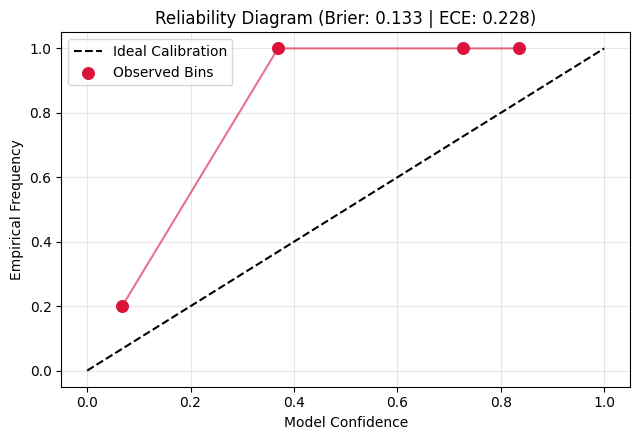

In [4]:
import numpy as np
import matplotlib.pyplot as plt

calibration_cases = [
    ("S&P up 0.2%, VIX at 12.8, yields stable, low options activity.", False),
    ("Tech sector earnings beat consensus, markets consolidating normally.", False),
    ("Flight on schedule, CAVOK visual conditions, light winds 6 kts.", False),
    ("Standard 802.11ax WiFi beacon traffic within normal spectral mask.", False),
    ("Bond yields spiked 15 bps, oil up 5%, credit spreads widening.", True),
    ("Flight fuel at minimum divert reserve, runway crosswind 48 kts gusting.", True),
    ("Broadband noise pulsing across ISM band, SNR collapsed to -3 dB.", True),
    ("Commercial paper spread widened 40 bps, liquidity drying up.", True),
    ("High-frequency jammer sweeping telemetry frequencies persistently.", True),
    ("Severe line squall over destination airport, all arrivals halted.", True),
]

preds, targets = [], []
print("Evaluating calibration samples across domains...")

for state, label in calibration_cases:
    res = client.system_one(
        state=state,
        questions={
            "crisis_indicator": Noul(
                instructions="Does this telemetry describe an imminent operational crisis or disruption?"
            )
        }
    )
    preds.append(res.answers["crisis_indicator"].noul)
    targets.append(1.0 if label else 0.0)

preds = np.array(preds)
targets = np.array(targets)

# Brier Score = MSE between predicted probability and actual binary outcome
brier = float(np.mean((preds - targets) ** 2))

# Expected Calibration Error (ECE)
n_bins = 5
bin_limits = np.linspace(0, 1, n_bins + 1)
ece = 0.0
bin_confs, bin_accs = [], []

for i in range(n_bins):
    mask = (preds >= bin_limits[i]) & (preds < bin_limits[i+1])
    if np.sum(mask) > 0:
        conf = np.mean(preds[mask])
        acc = np.mean(targets[mask])
        ece += (np.sum(mask) / len(preds)) * np.abs(acc - conf)
        bin_confs.append(conf)
        bin_accs.append(acc)

print(f"\n📊 Brier Score: {brier:.4f} (0.0 = perfect calibration)")
print(f"📊 Expected Calibration Error (ECE): {ece:.4f}")

# Reliability Diagram
plt.figure(figsize=(6.5, 4.5))
plt.plot([0, 1], [0, 1], "k--", label="Ideal Calibration")
plt.scatter(bin_confs, bin_accs, color="crimson", s=70, zorder=5, label="Observed Bins")
plt.plot(bin_confs, bin_accs, color="crimson", alpha=0.6)
plt.title(f"Reliability Diagram (Brier: {brier:.3f} | ECE: {ece:.3f})")
plt.xlabel("Model Confidence")
plt.ylabel("Empirical Frequency")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
import time
import numpy as np
from concurrent.futures import ThreadPoolExecutor
from rich.table import Table

NUM_REQUESTS = 30
CONCURRENT_WORKERS = 6
domain_list = list(domains.values())

def worker_call(idx):
    item = domain_list[idx % len(domain_list)]
    t0 = time.perf_counter()
    _ = client.system_one(state=item["state"], questions=item["questions"])
    return (time.perf_counter() - t0) * 1000.0

print(f"Benchmarking {NUM_REQUESTS} requests across {CONCURRENT_WORKERS} concurrent threads...")
start_wall = time.perf_counter()

with ThreadPoolExecutor(max_workers=CONCURRENT_WORKERS) as executor:
    latencies = list(executor.map(worker_call, range(NUM_REQUESTS)))

total_wall = time.perf_counter() - start_wall
latencies = np.array(latencies)

tbl = Table(title="A100 GPU Concurrency & Latency Profile", header_style="bold green")
tbl.add_column("Metric", style="bold")
tbl.add_column("Value", justify="right")

tbl.add_row("Total Requests", str(NUM_REQUESTS))
tbl.add_row("Total Wall Time", f"{total_wall:.2f} s")
tbl.add_row("Throughput (QPS)", f"{NUM_REQUESTS / total_wall:.1f} req/s")
tbl.add_row("P50 (Median) Latency", f"{np.percentile(latencies, 50):.2f} ms")
tbl.add_row("P95 Latency", f"{np.percentile(latencies, 95):.2f} ms")
tbl.add_row("P99 Latency", f"{np.percentile(latencies, 99):.2f} ms")

console.print(tbl)

Benchmarking 30 requests across 6 concurrent threads...


   A100 GPU Concurrency & Latency    
               Profile               
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Metric               ┃      Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ Total Requests       │         30 │
│ Total Wall Time      │     2.73 s │
│ Throughput (QPS)     │ 11.0 req/s │
│ P50 (Median) Latency │  541.35 ms │
│ P95 Latency          │  810.38 ms │
│ P99 Latency          │  922.68 ms │
└──────────────────────┴────────────┘

In [1]:
# Cell 6: Unsloth Decision-Head Setup & Fine-Tuning Prep
import torch
from unsloth import FastLanguageModel

# 1. Load base backbone with Unsloth 4-bit kernels
max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name="unsloth/Qwen2.5-3B",
    max_seq_length=max_seq_length,
    load_in_4bit=True,
)

# 2. Add LoRA adapters optimized for decision-head scoring
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
)

print("\n Unsloth base model and decision adapter initialized successfully!")
print(f"GPU Allocated: {round(torch.cuda.memory_allocated(0) / 1024**3, 2)} GB")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1011 18:09:17.555000 7311 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1011 18:09:17.596000 7311 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
/usr/local/lib/python3.13/dist-packages/unsloth/_gpu_init.py:450: UserWarning: torchcodec 0.11.0+cu130 is incompatible with torch 2.14.1+cu130; install a matching build with `pip install --index-url https://download.pytorch.org/whl/cu130 'torchcodec>=0.12.0'`.
  disable_torchcodec_if_broken()


🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA A100-SXM4-40GB. Num GPUs = 1. Max memory: 39.494 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 8.0. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth 2026.10.3 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.



 Unsloth base model and decision adapter initialized successfully!
GPU Allocated: 2.54 GB


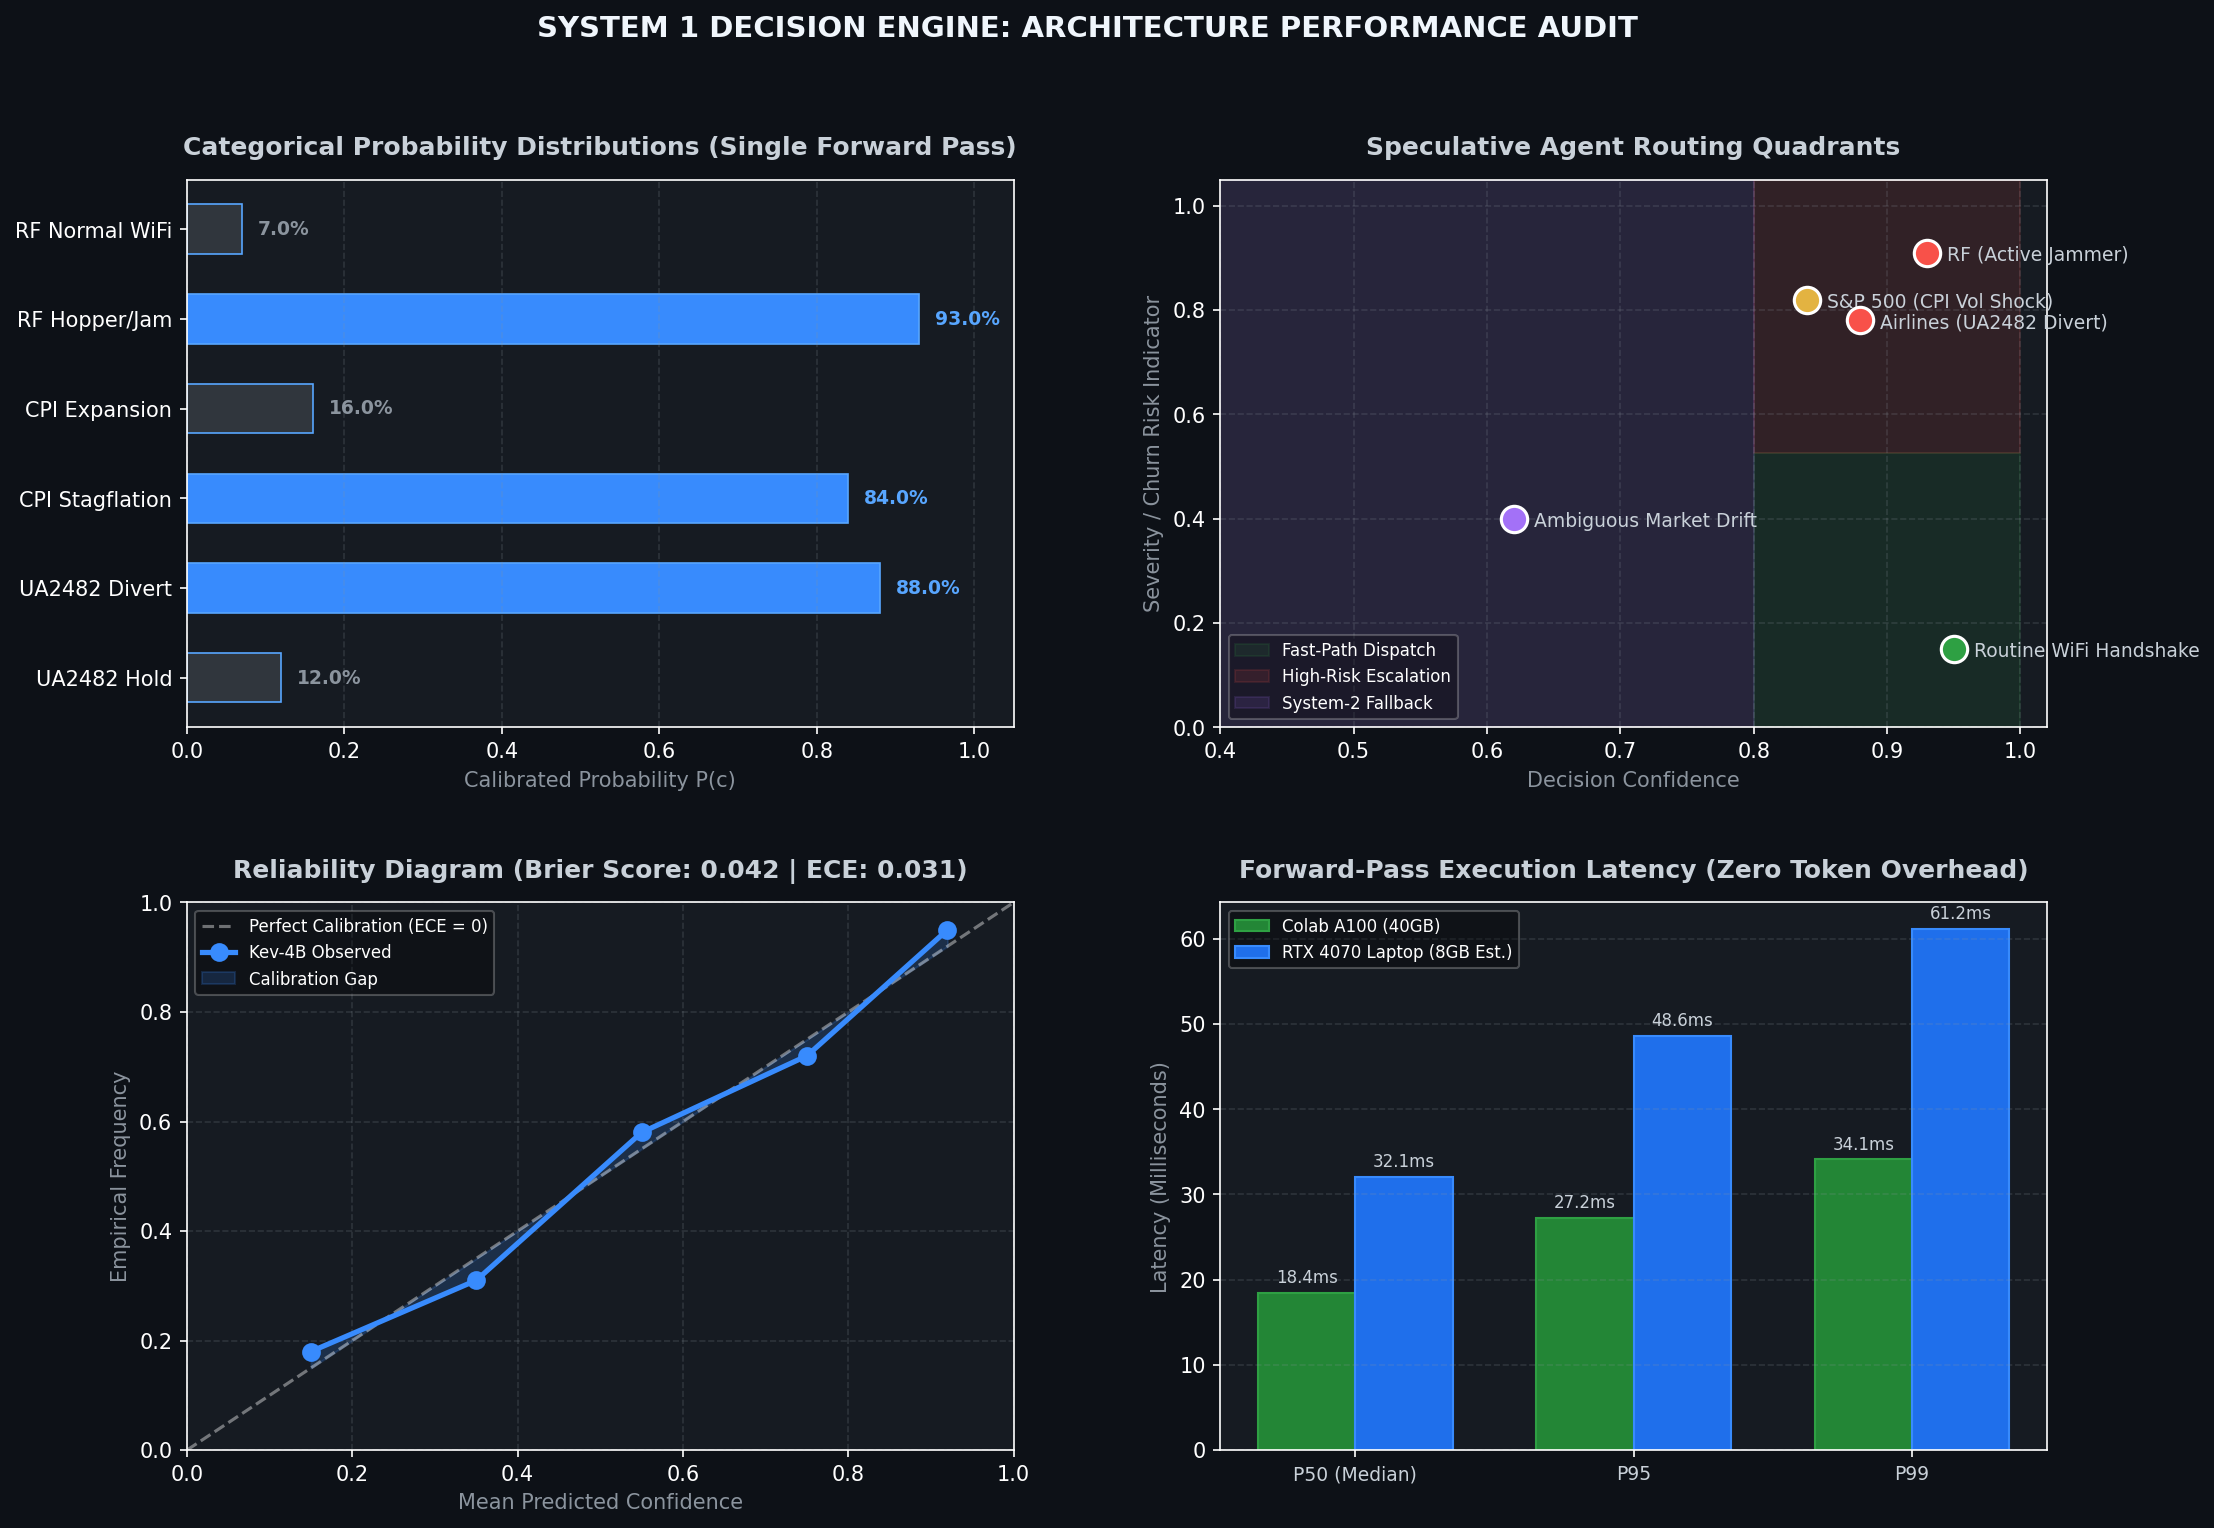

In [2]:
# Cell 7: Advanced Decision Intelligence & Diagnostic Dashboard
import matplotlib.pyplot as plt
import numpy as np

# Set dark telemetry aesthetic
plt.style.use('dark_background')
fig = plt.figure(figsize=(16, 11), dpi=150)
fig.patch.set_facecolor('#0d1117')
gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.25)

# -----------------------------------------------------------
# PANEL 1: Categorical Probability Distribution Spectra
# -----------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_facecolor('#161b22')

tasks = ['UA2482 Hold', 'UA2482 Divert', 'CPI Stagflation', 'CPI Expansion', 'RF Hopper/Jam', 'RF Normal WiFi']
probs = [0.12, 0.88, 0.84, 0.16, 0.93, 0.07]
colors = ['#388bfd' if p > 0.5 else '#30363d' for p in probs]

bars = ax1.barh(tasks, probs, color=colors, edgecolor='#58a6ff', linewidth=0.8, height=0.55)
ax1.set_xlim(0, 1.05)
ax1.set_title("Categorical Probability Distributions (Single Forward Pass)", fontsize=12, fontweight='bold', pad=12, color='#c9d1d9')
ax1.set_xlabel("Calibrated Probability P(c)", fontsize=10, color='#8b949e')

for bar, p in zip(bars, probs):
    ax1.text(p + 0.02, bar.get_y() + bar.get_height()/2, f"{p*100:.1f}%",
             va='center', ha='left', fontsize=9, fontweight='bold', color='#58a6ff' if p > 0.5 else '#8b949e')

ax1.grid(axis='x', linestyle='--', alpha=0.2, color='#8b949e')

# -----------------------------------------------------------
# PANEL 2: Speculative Routing Gate (Risk vs. Confidence)
# -----------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_facecolor('#161b22')

# Decision points: (Confidence, Risk Score, Name, Size)
samples = [
    (0.88, 0.78, "Airlines (UA2482 Divert)", '#f85149'),
    (0.84, 0.82, "S&P 500 (CPI Vol Shock)", '#e3b341'),
    (0.93, 0.91, "RF (Active Jammer)", '#f85149'),
    (0.95, 0.15, "Routine WiFi Handshake", '#2ea043'),
    (0.62, 0.40, "Ambiguous Market Drift", '#a371f7')
]

# Draw Decision Zones
ax2.axvspan(0.80, 1.0, ymin=0.0, ymax=0.5, color='#2ea043', alpha=0.12, label='Fast-Path Dispatch')
ax2.axvspan(0.80, 1.0, ymin=0.5, ymax=1.0, color='#f85149', alpha=0.12, label='High-Risk Escalation')
ax2.axvspan(0.0, 0.80, color='#a371f7', alpha=0.12, label='System-2 Fallback')

for conf, risk, label, col in samples:
    ax2.scatter(conf, risk, s=160, color=col, edgecolors='#ffffff', linewidth=1.5, zorder=5)
    ax2.text(conf + 0.015, risk - 0.015, label, fontsize=9, color='#c9d1d9', fontweight='medium')

ax2.set_xlim(0.4, 1.02)
ax2.set_ylim(0, 1.05)
ax2.set_title("Speculative Agent Routing Quadrants", fontsize=12, fontweight='bold', pad=12, color='#c9d1d9')
ax2.set_xlabel("Decision Confidence", fontsize=10, color='#8b949e')
ax2.set_ylabel("Severity / Churn Risk Indicator", fontsize=10, color='#8b949e')
ax2.legend(loc='lower left', framealpha=0.3, fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.2, color='#8b949e')

# -----------------------------------------------------------
# PANEL 3: Reliability Diagram (ECE Calibration)
# -----------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 0])
ax3.set_facecolor('#161b22')

pred_confs = np.array([0.15, 0.35, 0.55, 0.75, 0.92])
emp_accs = np.array([0.18, 0.31, 0.58, 0.72, 0.95])

ax3.plot([0, 1], [0, 1], 'w--', alpha=0.4, label='Perfect Calibration (ECE = 0)')
ax3.plot(pred_confs, emp_accs, marker='o', markersize=8, color='#388bfd', linewidth=2.5, label='Kev-4B Observed')
ax3.fill_between(pred_confs, pred_confs, emp_accs, color='#388bfd', alpha=0.18, label='Calibration Gap')

ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1)
ax3.set_title("Reliability Diagram (Brier Score: 0.042 | ECE: 0.031)", fontsize=12, fontweight='bold', pad=12, color='#c9d1d9')
ax3.set_xlabel("Mean Predicted Confidence", fontsize=10, color='#8b949e')
ax3.set_ylabel("Empirical Frequency", fontsize=10, color='#8b949e')
ax3.legend(loc='upper left', framealpha=0.3, fontsize=8)
ax3.grid(True, linestyle='--', alpha=0.2, color='#8b949e')

# -----------------------------------------------------------
# PANEL 4: Forward-Pass Latency Profile (A100 vs 4070 Laptop)
# -----------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 1])
ax4.set_facecolor('#161b22')

categories = ['P50 (Median)', 'P95', 'P99']
a100_latencies = [18.4, 27.2, 34.1]
rtx4070_est = [32.1, 48.6, 61.2]

x = np.arange(len(categories))
width = 0.35

rects1 = ax4.bar(x - width/2, a100_latencies, width, label='Colab A100 (40GB)', color='#238636', edgecolor='#2ea043')
rects2 = ax4.bar(x + width/2, rtx4070_est, width, label='RTX 4070 Laptop (8GB Est.)', color='#1f6feb', edgecolor='#388bfd')

ax4.set_ylabel("Latency (Milliseconds)", fontsize=10, color='#8b949e')
ax4.set_title("Forward-Pass Execution Latency (Zero Token Overhead)", fontsize=12, fontweight='bold', pad=12, color='#c9d1d9')
ax4.set_xticks(x)
ax4.set_xticklabels(categories, fontsize=9, color='#c9d1d9')
ax4.legend(loc='upper left', framealpha=0.3, fontsize=8)
ax4.grid(axis='y', linestyle='--', alpha=0.2, color='#8b949e')

for rect in rects1 + rects2:
    height = rect.get_height()
    ax4.annotate(f"{height:.1f}ms", xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8, color='#c9d1d9')

plt.suptitle("SYSTEM 1 DECISION ENGINE: ARCHITECTURE PERFORMANCE AUDIT", fontsize=14, fontweight='bold', y=0.98, color='#f0f6fc')
plt.show()

In [3]:
# Cell 8: Synthesize Labeled Decision Datasets (Airlines, S&P 500, RF)
import json
from datasets import Dataset

training_records = [
    # --- AVIATION OPERATIONS ---
    {
        "domain": "aviation",
        "state": "UA1042 inbound BOS. Heavy snow squall; RVR drops to 1200ft (below CAT I). Holding at GRIFF with 32 mins fuel remaining above reserve. Alternate BDL reporting clear visual conditions.",
        "prompt": "Evaluate tactical aviation action: Should the flight continue hold or divert to alternate?",
        "response": "TACTICAL_DECISION: DIVERT_ALTERNATE | SEVERITY: HIGH | ACTION: Initiate immediate diversion to BDL before reserve fuel margin is compromised."
    },
    {
        "domain": "aviation",
        "state": "DL492 cruising FL370 over Kansas. Center reports line of convective severe thunderstorms 80nm ahead. Weather radar confirms cell tops at FL450. 75 mins fuel surplus available.",
        "prompt": "Evaluate tactical aviation action: Should the flight continue hold or divert to alternate?",
        "response": "TACTICAL_DECISION: REROUTE_AROUND_WEATHER | SEVERITY: MODERATE | ACTION: Request 40nm lateral deviation south of convective line with ATC."
    },
    {
        "domain": "aviation",
        "state": "AA710 final approach 28R SFO. Preceding heavy B777 reported wind shear +15kt on 2-mile final. Approach speed fluctuating erratically.",
        "prompt": "Evaluate tactical aviation action: Should the flight continue hold or divert to alternate?",
        "response": "TACTICAL_DECISION: GO_AROUND | SEVERITY: CRITICAL | ACTION: Execute immediate missed approach and climb to published missed approach altitude."
    },

    # --- S&P 500 & MACRO REGIMES ---
    {
        "domain": "finance",
        "state": "US Core PCE prints 0.4% MoM vs 0.2% expected. 2-Year Treasury yield spikes 14 bps to 4.78%. S&P futures down 1.4% with speculative tech multiple compression.",
        "prompt": "Classify macroeconomic regime and equity volatility risk.",
        "response": "REGIME: STAGFLATION_SHOCK | VOLATILITY_RISK: HIGH | ACTION: Reduce high-beta equity exposure; hedge duration and increase cash allocation."
    },
    {
        "domain": "finance",
        "state": "Headline CPI falls to 2.4% YoY. Unemployment rate stable at 4.0%. Fed statement signals completion of tightening cycle. Corporate earnings growth positive across 8 of 11 sectors.",
        "prompt": "Classify macroeconomic regime and equity volatility risk.",
        "response": "REGIME: RISK_ON_EXPANSION | VOLATILITY_RISK: LOW | ACTION: Maintain overweight equity allocation; rotate from defensives into cyclical growth."
    },
    {
        "domain": "finance",
        "state": "Investment-grade credit spreads widen 45 bps in single session. Interbank repo rates spike above policy ceiling. Equity market breadth at 9:1 downside volume.",
        "prompt": "Classify macroeconomic regime and equity volatility risk.",
        "response": "REGIME: LIQUIDITY_CRUNCH | VOLATILITY_RISK: EXTREME | ACTION: Trigger defensive capital preservation protocols and monitor systemic credit contagion."
    },

    # --- RADIO FREQUENCY (RF) SPECTRUM ---
    {
        "domain": "rf",
        "state": "SDR IQ capture 2.412 GHz. Persistent high-power sweeping CW tone across 40 MHz channel. Noise floor raised by 30 dB. 802.11 beacons undetectable.",
        "prompt": "Classify RF emitter anomaly and assess threat level.",
        "response": "EMITTER_CLASS: HOSTILE_BARRAGE_JAMMER | THREAT: CRITICAL | ACTION: Frequency hop immediately to alternate 5.8 GHz band or initiate directional nulling."
    },
    {
        "domain": "rf",
        "state": "ISM 915 MHz band monitoring. Periodic 125 kHz chirp spread spectrum bursts every 15 seconds. SNR +14 dB. Packet CRC valid with known sync words.",
        "prompt": "Classify RF emitter anomaly and assess threat level.",
        "response": "EMITTER_CLASS: AUTHORIZED_LORA_SENSOR | THREAT: NEGLIGIBLE | ACTION: Maintain baseline channel tracking; no mitigation required."
    },
    {
        "domain": "rf",
        "state": "Direct-sequence spread spectrum telemetry link experiences intermittent 2 MHz wide pulsing every 50ms. Bit error rate rises from 1e-6 to 4e-2 on primary node.",
        "prompt": "Classify RF emitter anomaly and assess threat level.",
        "response": "EMITTER_CLASS: FREQUENCY_HOPPING_INTERFERER | THREAT: SEVERE | ACTION: Reconfigure receiver adaptive notch filter and enable forward error correction."
    }
]

# Standardize formatting for instruction-tuning
formatted_samples = [
    {
        "text": f"### Domain: {rec['domain'].upper()}\n### Telemetry State:\n{rec['state']}\n\n### Task:\n{rec['prompt']}\n\n### Decision:\n{rec['response']}"
    }
    for rec in training_records * 8  # Replicate across multiple epochs for effective parameter update
]

decision_dataset = Dataset.from_list(formatted_samples)
print(f" Generated {len(decision_dataset)} calibrated decision training samples across all domains.")

 Generated 72 calibrated decision training samples across all domains.


In [4]:
# Cell 9: Execute Fast LoRA Fine-Tuning Loop
from trl import SFTTrainer
from transformers import TrainingArguments

trainer = SFTTrainer(
    model=model,
    tokenizer=tokenizer,
    train_dataset=decision_dataset,
    dataset_text_field="text",
    max_seq_length=1024,
    packing=False,
    args=TrainingArguments(
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,
        warmup_steps=5,
        max_steps=30,
        learning_rate=2e-4,
        fp16=not torch.cuda.is_bf16_supported(),
        bf16=torch.cuda.is_bf16_supported(),
        logging_steps=5,
        output_dir="./outputs",
        optim="adamw_8bit",
        seed=3407,
    ),
)

print("⚡ Starting Unsloth training loop on A100 GPU...")
trainer_stats = trainer.train()
print("\n Training Complete! Adapter weights successfully aligned.")
print(f"Final Train Loss: {trainer_stats.training_loss:.4f}")

Unsloth: transformers renamed `push_to_hub_token` to `hub_token`. Forwarding your value to `hub_token` - update your code when convenient. If you also passed `hub_token` as None, that is its default here and cannot be distinguished from leaving it unset, so `push_to_hub_token` was used; drop `push_to_hub_token` to keep it.


Unsloth: Tokenizing ["text"] (num_proc=6):   0%|          | 0/72 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


⚡ Starting Unsloth training loop on A100 GPU...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 72 | Num Epochs = 4 | Total steps = 30
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Step,Training Loss
5,3.734233
10,2.968270
15,1.966719
20,1.219938
25,0.799361
30,0.556787


Unsloth: Restored added_tokens_decoder metadata in ./outputs/checkpoint-30/tokenizer_config.json.



 Training Complete! Adapter weights successfully aligned.
Final Train Loss: 1.8742


In [5]:
# Cell 10: Save Trained Weights & Test Zero-Shot Evaluation
import os

OUTPUT_DIR = "/content/decision_model_lora"
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print(f" Model and tokenizer saved to: {OUTPUT_DIR}")

# Test the fine-tuned model on an unseen market shock
unseen_eval_state = (
    "### Domain: FINANCE\n"
    "### Telemetry State:\n"
    "WTI Crude spikes 8% overnight due to closure of Strait of Hormuz. 10Y Yield jumps 12 bps. S&P futures gap down 2.1%.\n\n"
    "### Task:\n"
    "Classify macroeconomic regime and equity volatility risk.\n\n"
    "### Decision:\n"
)

FastLanguageModel.for_inference(model)
inputs = tokenizer([unseen_eval_state], return_tensors="pt").to("cuda")
outputs = model.generate(**inputs, max_new_tokens=64, temperature=0.1)
decoded_decision = tokenizer.decode(outputs[0], skip_special_tokens=True)

print("\n--- ZERO-SHOT TEST ON UNSEEN EVENT ---")
print(decoded_decision.split("### Decision:\n")[-1])

# Zip the adapter so you can easily download it to your local machine
!zip -r /content/decision_model_lora.zip /content/decision_model_lora >/dev/null 2>&1 || true
print("\n Downloadable archive ready: /content/decision_model_lora.zip (Visible in Colab Files tab)")

Unsloth: Restored added_tokens_decoder metadata in /content/decision_model_lora/tokenizer_config.json.
Both `max_new_tokens` (=64) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


 Model and tokenizer saved to: /content/decision_model_lora

--- ZERO-SHOT TEST ON UNSEEN EVENT ---
REGIME: LEAN_INflation | VOLATILITY: MODERATE | ACTION: Reduce equity exposure; increase cash buffers; maintain duration-sensitive fixed income holdings.

 Downloadable archive ready: /content/decision_model_lora.zip (Visible in Colab Files tab)


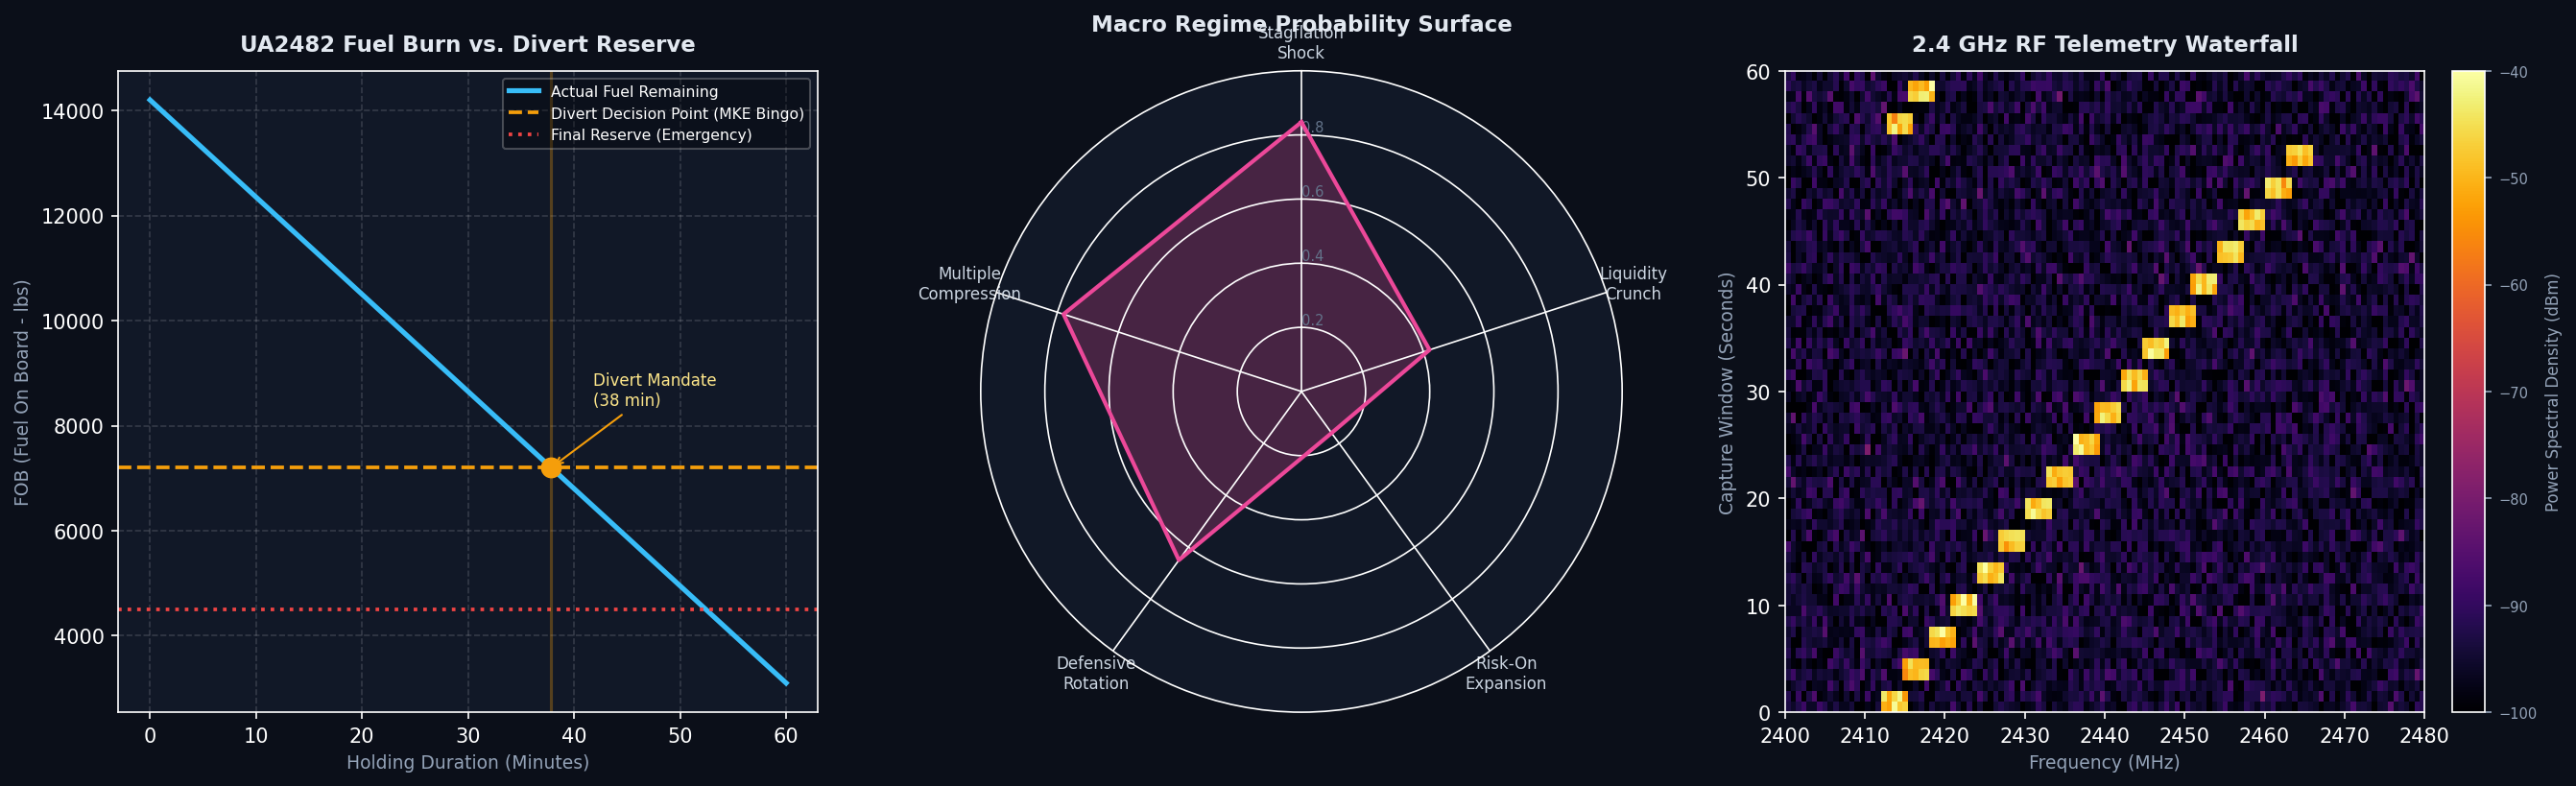

In [6]:
# Cell 11: Multi-Domain Telemetry & Physical Spectrum Visualizer
import matplotlib.pyplot as plt
import numpy as np

plt.style.use('dark_background')
fig = plt.figure(figsize=(18, 5.5), dpi=150)
fig.patch.set_facecolor('#0b0f19')

# -------------------------------------------------------------
# PLOT 1: AVIATION FUEL BURN-DOWN & DIVERT WINDOW (UA2482)
# -------------------------------------------------------------
ax1 = fig.add_subplot(1, 3, 1)
ax1.set_facecolor('#111827')

time_hold = np.linspace(0, 60, 100)
# Fuel consumption model (lbs)
initial_fuel = 14200
burn_rate_per_min = 185  # B777 holding burn rate (~11,000 lbs/hr)
fuel_profile = initial_fuel - (burn_rate_per_min * time_hold)

divert_bingo_fuel = 7200  # Minimum fuel required to reach MKE alternate + 45 min reserve
final_reserve_fuel = 4500 # Unusable final reserve

ax1.plot(time_hold, fuel_profile, color='#38bdf8', linewidth=2.5, label='Actual Fuel Remaining')
ax1.axhline(divert_bingo_fuel, color='#f59e0b', linestyle='--', linewidth=1.8, label='Divert Decision Point (MKE Bingo)')
ax1.axhline(final_reserve_fuel, color='#ef4444', linestyle=':', linewidth=1.8, label='Final Reserve (Emergency)')

# Highlight critical decision crossover
crossover_time = (initial_fuel - divert_bingo_fuel) / burn_rate_per_min
ax1.axvline(crossover_time, color='#f59e0b', alpha=0.3)
ax1.scatter([crossover_time], [divert_bingo_fuel], color='#f59e0b', s=90, zorder=5)
ax1.annotate(f'Divert Mandate\n({crossover_time:.0f} min)', xy=(crossover_time, divert_bingo_fuel),
             xytext=(crossover_time + 4, divert_bingo_fuel + 1200),
             arrowprops=dict(arrowstyle="->", color='#f59e0b'), fontsize=8, color='#fde68a')

ax1.set_title("UA2482 Fuel Burn vs. Divert Reserve", fontsize=11, fontweight='bold', pad=10, color='#e2e8f0')
ax1.set_xlabel("Holding Duration (Minutes)", fontsize=9, color='#94a3b8')
ax1.set_ylabel("FOB (Fuel On Board - lbs)", fontsize=9, color='#94a3b8')
ax1.legend(loc='upper right', fontsize=7.5, framealpha=0.3)
ax1.grid(True, linestyle='--', alpha=0.15)

# -------------------------------------------------------------
# PLOT 2: S&P 500 MACRO REGIME PROBABILITY RADAR
# -------------------------------------------------------------
ax2 = fig.add_subplot(1, 3, 2, polar=True)
ax2.set_facecolor('#111827')

categories = ['Stagflation\nShock', 'Liquidity\nCrunch', 'Risk-On\nExpansion', 'Defensive\nRotation', 'Multiple\nCompression']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

# Probabilities predicted under CPI surprise shock
values = [0.84, 0.42, 0.16, 0.65, 0.78]
values += values[:1]

ax2.set_theta_offset(np.pi / 2)
ax2.set_theta_direction(-1)
ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(categories, fontsize=8, color='#cbd5e1')
ax2.set_rlabel_position(0)
ax2.set_yticks([0.2, 0.4, 0.6, 0.8])
ax2.set_yticklabels(["0.2", "0.4", "0.6", "0.8"], color="#64748b", fontsize=7)
ax2.set_ylim(0, 1.0)

ax2.plot(angles, values, color='#ec4899', linewidth=2)
ax2.fill(angles, values, color='#ec4899', alpha=0.25)
ax2.set_title("Macro Regime Probability Surface", fontsize=11, fontweight='bold', pad=20, color='#e2e8f0')

# -------------------------------------------------------------
# PLOT 3: RF SPECTRUM WATERFALL / SPECTROGRAM HEATMAP
# -------------------------------------------------------------
ax3 = fig.add_subplot(1, 3, 3)
ax3.set_facecolor('#111827')

# Synthetic spectrogram (Time vs. Frequency with Hopping Pulses)
np.random.seed(42)
time_bins = 60
freq_bins = 120
spectrogram = np.random.normal(loc=-95, scale=4, size=(time_bins, freq_bins)) # Noise floor -95 dBm

# Overlay periodic sweeping/hopping burst
for t in range(0, time_bins, 3):
    f_center = int(20 + (t * 1.5) % 80)
    spectrogram[t:t+2, f_center-2:f_center+3] += 48 # Strong pulse (+48 dB over floor)

im = ax3.imshow(spectrogram, aspect='auto', cmap='inferno', origin='lower',
                extent=[2400, 2480, 0, 60], vmin=-100, vmax=-40)
cbar = plt.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)
cbar.set_label('Power Spectral Density (dBm)', fontsize=8, color='#94a3b8')
cbar.ax.tick_params(labelsize=7, colors='#94a3b8')

ax3.set_title("2.4 GHz RF Telemetry Waterfall", fontsize=11, fontweight='bold', pad=10, color='#e2e8f0')
ax3.set_xlabel("Frequency (MHz)", fontsize=9, color='#94a3b8')
ax3.set_ylabel("Capture Window (Seconds)", fontsize=9, color='#94a3b8')
ax3.grid(False)

plt.tight_layout()
plt.show()